In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

plt.style.use('ggplot')

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("insurance.csv")

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
print("Dataset Shape:", df.shape)

print("\nDataset Information")
print(df.info())

print("\nMissing Values")
print(df.isnull().sum())

print("\nStatistical Summary")
print(df.describe())

Dataset Shape: (1338, 7)

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None

Missing Values
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Statistical Summary
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000 

In [ ]:
X = df[['bmi' ] ]
y = df['charges' ]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("Training Samples :", len(X_train))
print("Testing Samples :", len(X_test))

Training Samples : 1070
Testing Samples : 268


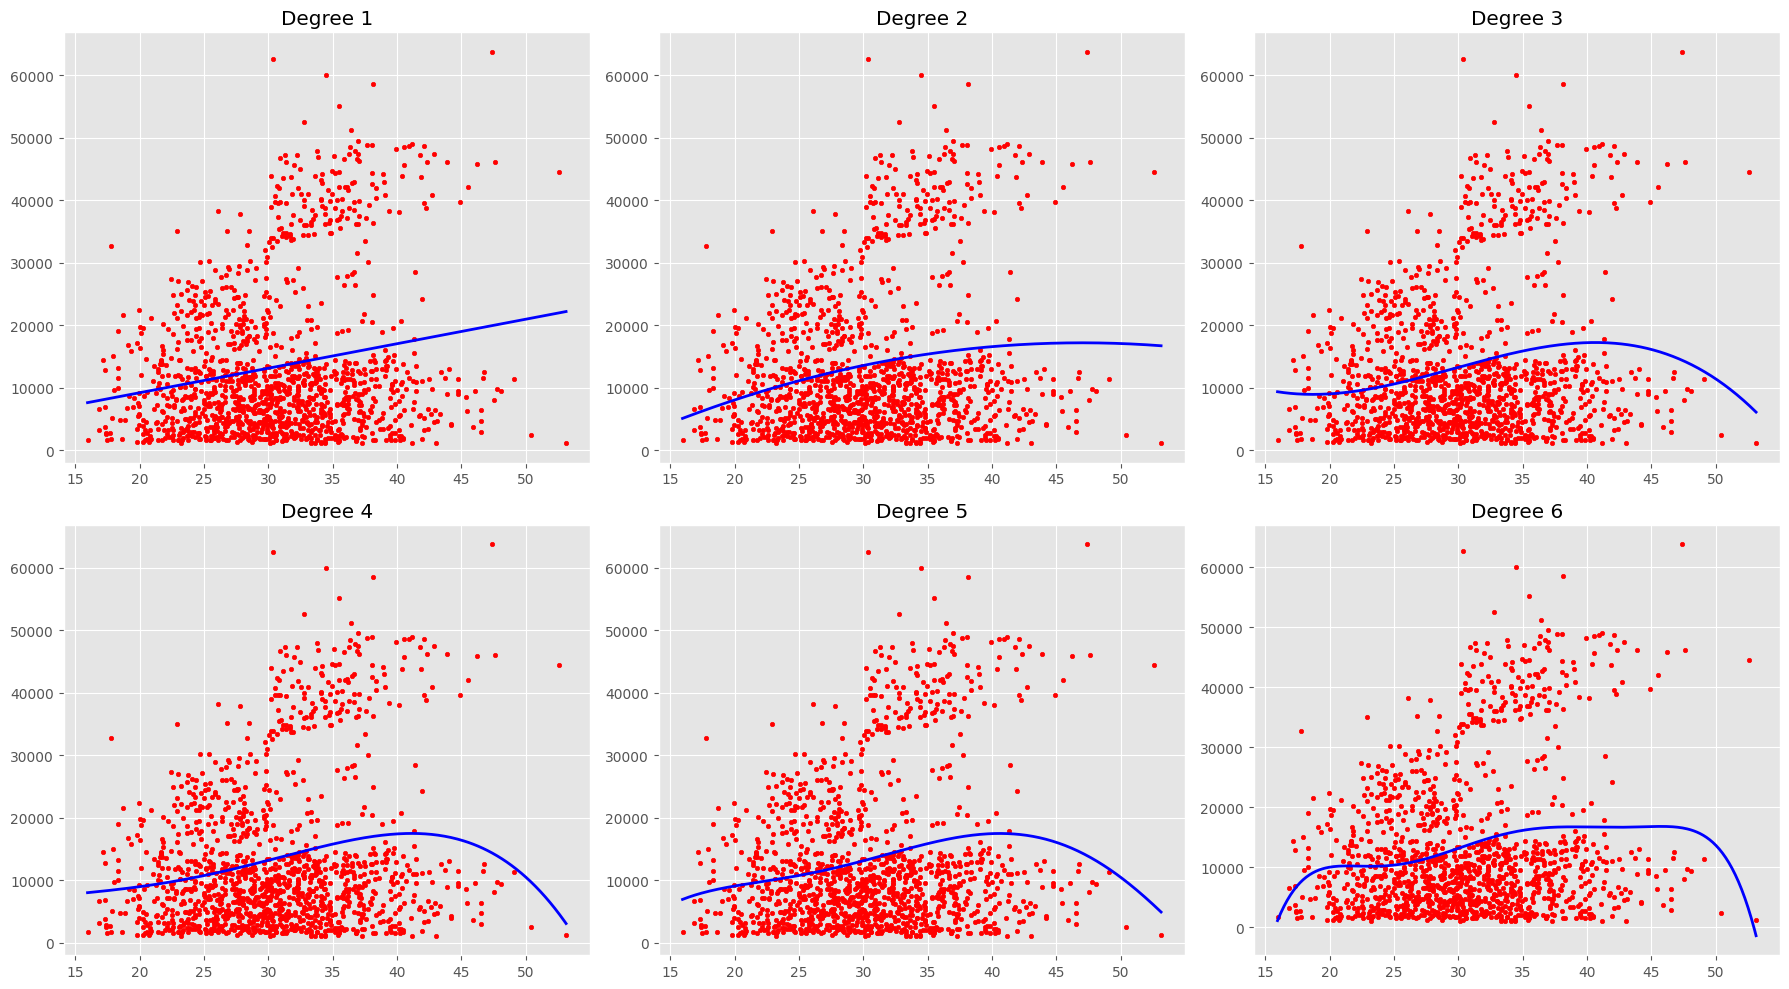

In [ ]:
degrees = [1, 2, 3, 4, 5, 6]
results = []
plt.figure(figsize=(18,10))

x_grid = np.linspace(X.min(), X.max(), 300).reshape(-1,1)

for degree in degrees:
  poly = PolynomialFeatures (degree)

  X_poly_train = poly.fit_transform(X_train)
  model = LinearRegression()
  model.fit(X_poly_train, y_train)

  y_pred = model.predict(poly. transform(X_test))

  mse = mean_squared_error(y_test, y_pred)
  rmse = np.sqrt(mse)
  r2 = r2_score(y_test, y_pred)

  results.append([degree, mse, rmse, r2])

  plt.subplot(2,3,degree)
  plt.scatter(X, y, color='red', s=10)
  plt.plot(x_grid, model.predict(poly.transform(x_grid)),color = 'blue',linewidth = 2)
  plt.title(f"Degree {degree}")

plt.tight_layout()
plt.show()

In [ ]:
results_df = pd.DataFrame( results, columns=["Degree", "MSE", "RMSE", "R2 Score"])
results_df

,Degree,MSE,RMSE,R2 Score
0,1,1.490851e+08,12210.039191,0.039702
1,2,1.504728e+08,12266.733504,0.030763
2,3,1.524525e+08,12347.166300,0.018011
3,4,1.531528e+08,12375.489932,0.013501
4,5,1.526792e+08,12356.343313,0.016551
5,6,1.538510e+08,12403.667082,0.009003


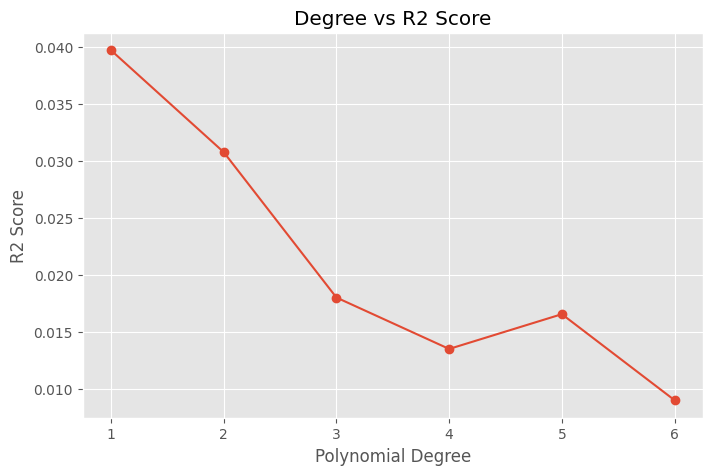

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(results_df["Degree"],
results_df["R2 Score"],
marker='o')

plt.xlabel("Polynomial Degree")
plt.ylabel("R2 Score")
plt.title("Degree vs R2 Score")
plt.grid(True)

plt.show()

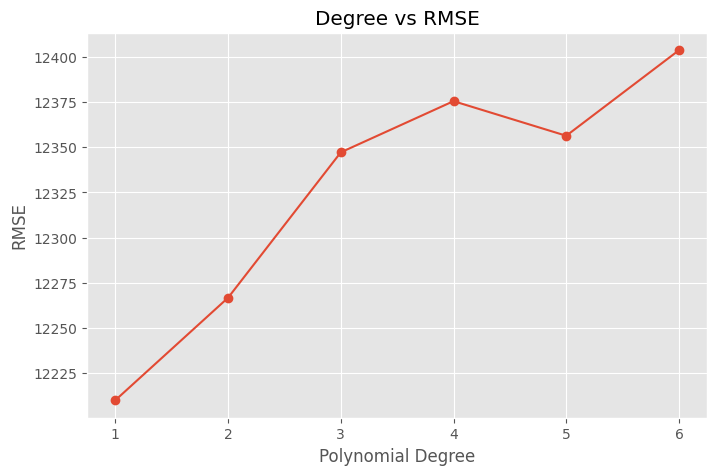

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(results_df["Degree"],
results_df["RMSE"],
marker='o')

plt.xlabel("Polynomial Degree")
plt.ylabel("RMSE")
plt.title("Degree vs RMSE")
plt.grid(True)

plt.show()